In [ ]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/CENG400_Energy_Project")

if PROJECT.exists():
    print("Project folder found:")
    for item in PROJECT.rglob("*"):
        if item.is_file():
            print(item.relative_to(PROJECT))
else:
    print("Folder not found.")
print("Check the folder name and location in My Drive.")

Streaming output truncated to the last 5000 lines.
person2_outputs/curated/electricity_long/date=2016-10-12/part-00010-50de2aa4-0c16-4624-be3c-add9d5ac2377.c000.csv
person2_outputs/curated/electricity_long/date=2016-10-12/.part-00010-50de2aa4-0c16-4624-be3c-add9d5ac2377.c000.csv.crc
person2_outputs/curated/electricity_long/date=2016-10-12/.part-00011-50de2aa4-0c16-4624-be3c-add9d5ac2377.c000.csv.crc
person2_outputs/curated/electricity_long/date=2017-12-22/.part-00005-50de2aa4-0c16-4624-be3c-add9d5ac2377.c000.csv.crc
person2_outputs/curated/electricity_long/date=2017-12-22/.part-00011-50de2aa4-0c16-4624-be3c-add9d5ac2377.c000.csv.crc
person2_outputs/curated/electricity_long/date=2017-12-22/part-00003-50de2aa4-0c16-4624-be3c-add9d5ac2377.c000.csv
person2_outputs/curated/electricity_long/date=2017-12-22/part-00001-50de2aa4-0c16-4624-be3c-add9d5ac2377.c000.csv
person2_outputs/curated/electricity_long/date=2017-12-22/part-00010-50de2aa4-0c16-4624-be3c-add9d5ac2377.c000.csv
person2_outputs/c

In [ ]:
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/CENG400_Energy_Project")

folders = [
    "raw",
    "person2_outputs/curated",
    "person2_outputs/quality",
    "person2_outputs/analytics",
    "person2_outputs/features"
]

for folder in folders:
    path = PROJECT / folder
    files = list(path.rglob("*")) if path.exists() else []
    files = [f for f in files if f.is_file()]

    print(f"\n{folder}")
    print("Exists:", path.exists())
    print("Files:", len(files))

    for file in files[:10]:
        print(" -", file.name)


raw
Exists: True
Files: 2
 - metadata.csv
 - electricity.csv

person2_outputs/curated
Exists: True
Files: 17546
 - ._SUCCESS.crc
 - _SUCCESS
 - .part-00001-50de2aa4-0c16-4624-be3c-add9d5ac2377.c000.csv.crc
 - part-00000-50de2aa4-0c16-4624-be3c-add9d5ac2377.c000.csv
 - .part-00000-50de2aa4-0c16-4624-be3c-add9d5ac2377.c000.csv.crc
 - part-00001-50de2aa4-0c16-4624-be3c-add9d5ac2377.c000.csv
 - part-00002-50de2aa4-0c16-4624-be3c-add9d5ac2377.c000.csv
 - .part-00002-50de2aa4-0c16-4624-be3c-add9d5ac2377.c000.csv.crc
 - part-00003-50de2aa4-0c16-4624-be3c-add9d5ac2377.c000.csv
 - .part-00003-50de2aa4-0c16-4624-be3c-add9d5ac2377.c000.csv.crc

person2_outputs/quality
Exists: True
Files: 4
 - part-00000-5b864b15-298c-463c-ad75-d3974691e005-c000.csv
 - .part-00000-5b864b15-298c-463c-ad75-d3974691e005-c000.csv.crc
 - ._SUCCESS.crc
 - _SUCCESS

person2_outputs/analytics
Exists: True
Files: 46
 - part-00001-fc5b3a93-3f09-42fe-a904-300f7d2abff6-c000.csv
 - part-00000-fc5b3a93-3f09-42fe-a904-300f7d2ab

In [ ]:
from pyspark.sql import SparkSession

try:
    spark
except NameError:
    spark = (
        SparkSession.builder
        .appName("FastInspection")
        .getOrCreate()
    )

PROJECT = "/content/drive/MyDrive/CENG400_Energy_Project"
OUT = f"{PROJECT}/person2_outputs"

def quick_check(folder):
    print("\nCHECKING:", folder)

    try:
        df = (
            spark.read
            .option("header", True)
            .option("inferSchema", True)
            .option("recursiveFileLookup", True)
            .csv(f"{OUT}/{folder}")
        )

        print("Columns:", df.columns)
        df.limit(5).show(truncate=False)

    except Exception as e:
        print("Skipped:", str(e)[:200])

# Do not scan the huge curated folder yet
quick_check("quality")
quick_check("analytics")
quick_check("features")


CHECKING: quality
Columns: ['field', 'type', 'definition']
+-----------+---------+------------------------------------------+
|field      |type     |definition                                |
+-----------+---------+------------------------------------------+
|timestamp  |timestamp|Source timestamp parsed as Spark timestamp|
|date       |date     |Calendar date                             |
|building_id|string   |Unique BDG2 meter/building identifier     |
|kwh        |double   |Energy consumed during the hourly interval|
|hour       |integer  |Hour of day, 0-23                         |
+-----------+---------+------------------------------------------+


CHECKING: analytics
Columns: ['building_id', 'timestamp', 'energy_kwh', 'peak_demand_kw', 'minimum_demand_kw', 'average_demand_kw', 'readings', 'anomaly_count', 'load_factor']
+--------------------+------------------------+----------+--------------+-----------------+-----------------+--------+-------------+-----------+
|building_id  

In [ ]:
# ============================================================
# STEP 1 — BENCHMARK SETUP AND WORKLOAD INFORMATION
# ============================================================

from pathlib import Path
import json
import pandas as pd

PROJECT = Path("/content/drive/MyDrive/CENG400_Energy_Project")
BENCHMARK_DIR = PROJECT / "person3_benchmarks"
BENCHMARK_DIR.mkdir(exist_ok=True)

raw_electricity = PROJECT / "raw" / "electricity.csv"
raw_metadata = PROJECT / "raw" / "metadata.csv"

setup = {
    "environment": "Google Colab single-node Spark",
    "storage": "Google Drive",
    "dataset": "Building Data Genome Project 2",
    "electricity_file": str(raw_electricity),
    "metadata_file": str(raw_metadata),
    "electricity_size_mb": round(
        raw_electricity.stat().st_size / (1024 * 1024), 2
    ),
    "metadata_size_mb": round(
        raw_metadata.stat().st_size / (1024 * 1024), 2
    ),
    "spark_version": spark.version,
    "workloads": [
        "Small: 500 timestamps",
        "Medium: 5,000 timestamps",
        "Full: all timestamps"
    ]
}

setup_df = pd.DataFrame([setup])
display(setup_df.T)

setup_path = BENCHMARK_DIR / "benchmark_setup.json"

with open(setup_path, "w") as file:
    json.dump(setup, file, indent=4)

print("Benchmark setup saved to:")
print(setup_path)

,0
environment,Google Colab single-node Spark
storage,Google Drive
dataset,Building Data Genome Project 2
electricity_file,/content/drive/MyDrive/CENG400_Energy_Project/...
metadata_file,/content/drive/MyDrive/CENG400_Energy_Project/...
electricity_size_mb,166.17
metadata_size_mb,0.26
spark_version,4.0.5
workloads,"[Small: 500 timestamps, Medium: 5,000 timestam..."


Benchmark setup saved to:
/content/drive/MyDrive/CENG400_Energy_Project/person3_benchmarks/benchmark_setup.json


In [ ]:
# ============================================================
# STEP 2 — INPUT DATASET DIMENSIONS
# ============================================================

import time
import pandas as pd
from pyspark.sql import functions as F

start = time.perf_counter()

electricity_input = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .csv(str(raw_electricity))
)

metadata_input = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .csv(str(raw_metadata))
)

electricity_rows = electricity_input.count()
metadata_rows = metadata_input.count()

runtime = time.perf_counter() - start

input_results = pd.DataFrame([{
    "file": "electricity.csv",
    "rows": electricity_rows,
    "columns": len(electricity_input.columns),
    "size_mb": setup["electricity_size_mb"]
}, {
    "file": "metadata.csv",
    "rows": metadata_rows,
    "columns": len(metadata_input.columns),
    "size_mb": setup["metadata_size_mb"]
}])

display(input_results)

input_results.to_csv(
    BENCHMARK_DIR / "input_dataset_dimensions.csv",
    index=False
)

print("Input reading time:", round(runtime, 3), "seconds")
print("Saved:", BENCHMARK_DIR / "input_dataset_dimensions.csv")

,file,rows,columns,size_mb
0,electricity.csv,17544,1579,166.17
1,metadata.csv,1636,32,0.26


Input reading time: 11.227 seconds
Saved: /content/drive/MyDrive/CENG400_Energy_Project/person3_benchmarks/input_dataset_dimensions.csv


In [ ]:
# ============================================================
# STEP 3 — SMALL WORKLOAD: 500 TIMESTAMPS
# ============================================================

import time
from pyspark.sql import functions as F

def run_workload(workload_name, timestamp_limit):
    start_total = time.perf_counter()

    data = (
        spark.read
        .option("header", True)
        .option("inferSchema", True)
        .csv(str(raw_electricity))
        .limit(timestamp_limit)
    )

    input_rows = data.count()

    meter_columns = [
        c for c in data.columns
        if c != "timestamp"
    ]

    casted = data.select(
        "timestamp",
        *[
            F.col(c).cast("double").alias(c)
            for c in meter_columns
        ]
    )

    stack_expression = ", ".join(
        [f"'{c}', `{c}`" for c in meter_columns]
    )

    long_data = casted.selectExpr(
        "timestamp",
        f"stack({len(meter_columns)}, {stack_expression}) "
        "as (building_id, kwh)"
    )

    cleaned = (
        long_data
        .filter(F.col("timestamp").isNotNull())
        .filter(F.col("building_id").isNotNull())
        .filter(F.col("kwh").isNotNull())
        .filter(F.col("kwh") >= 0)
    )

    daily_summary = (
        cleaned
        .withColumn("date", F.to_date("timestamp"))
        .groupBy("date", "building_id")
        .agg(
            F.sum("kwh").alias("daily_kwh"),
            F.avg("kwh").alias("average_kwh"),
            F.max("kwh").alias("maximum_kwh"),
            F.count("*").alias("reading_count")
        )
    )

    output_rows = daily_summary.count()
    total_runtime = time.perf_counter() - start_total

    result = {
        "environment": "Single-node Spark",
        "workload": workload_name,
        "timestamps": input_rows,
        "meter_columns": len(meter_columns),
        "long_rows": input_rows * len(meter_columns),
        "summary_rows": output_rows,
        "runtime_seconds": round(total_runtime, 3),
        "throughput_rows_per_second": round(
            (input_rows * len(meter_columns)) / total_runtime, 2
        )
    }

    print(result)
    return result

small_result = run_workload("Small", 500)

{'environment': 'Single-node Spark', 'workload': 'Small', 'timestamps': 500, 'meter_columns': 1578, 'long_rows': 789000, 'summary_rows': 31821, 'runtime_seconds': 26.904, 'throughput_rows_per_second': 29326.79}


In [ ]:
# ============================================================
# STEP 4 — MEDIUM WORKLOAD: 5,000 TIMESTAMPS
# ============================================================

medium_result = run_workload("Medium", 5000)

{'environment': 'Single-node Spark', 'workload': 'Medium', 'timestamps': 5000, 'meter_columns': 1578, 'long_rows': 7890000, 'summary_rows': 311703, 'runtime_seconds': 37.491, 'throughput_rows_per_second': 210448.37}


In [ ]:
# ============================================================
# STEP 5 — SAVE SMALL AND MEDIUM RESULTS
# ============================================================

import pandas as pd

single_node_results = pd.DataFrame([
    small_result,
    medium_result
])

display(single_node_results)

results_path = BENCHMARK_DIR / "single_node_small_medium.csv"

single_node_results.to_csv(
    results_path,
    index=False
)

print("Benchmark results saved to:")
print(results_path)

,environment,workload,timestamps,meter_columns,long_rows,summary_rows,runtime_seconds,throughput_rows_per_second
0,Single-node Spark,Small,500,1578,789000,31821,26.904,29326.79
1,Single-node Spark,Medium,5000,1578,7890000,311703,37.491,210448.37


Benchmark results saved to:
/content/drive/MyDrive/CENG400_Energy_Project/person3_benchmarks/single_node_small_medium.csv


In [ ]:
# ============================================================
# STEP 6 — RUN FULL WORKLOAD
# ============================================================

full_result = run_workload("Full", 17544)

print(full_result)

{'environment': 'Single-node Spark', 'workload': 'Full', 'timestamps': 17544, 'meter_columns': 1578, 'long_rows': 27684432, 'summary_rows': 1101288, 'runtime_seconds': 62.434, 'throughput_rows_per_second': 443421.03}
{'environment': 'Single-node Spark', 'workload': 'Full', 'timestamps': 17544, 'meter_columns': 1578, 'long_rows': 27684432, 'summary_rows': 1101288, 'runtime_seconds': 62.434, 'throughput_rows_per_second': 443421.03}


In [ ]:
# ============================================================
# STEP 7 — SAVE ALL SINGLE-NODE RESULTS
# ============================================================

single_node_results = pd.DataFrame([
    small_result,
    medium_result,
    full_result
])

display(single_node_results)

results_path = BENCHMARK_DIR / "single_node_all_workloads.csv"

single_node_results.to_csv(
    results_path,
    index=False
)

print("All single-node benchmark results saved to:")
print(results_path)

,environment,workload,timestamps,meter_columns,long_rows,summary_rows,runtime_seconds,throughput_rows_per_second
0,Single-node Spark,Small,500,1578,789000,31821,26.904,29326.79
1,Single-node Spark,Medium,5000,1578,7890000,311703,37.491,210448.37
2,Single-node Spark,Full,17544,1578,27684432,1101288,62.434,443421.03


All single-node benchmark results saved to:
/content/drive/MyDrive/CENG400_Energy_Project/person3_benchmarks/single_node_all_workloads.csv


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

results_path = (
    "/content/drive/MyDrive/CENG400_Energy_Project/"
    "person3_benchmarks/single_node_all_workloads.csv"
)

results = pd.read_csv(results_path)

display(results)


,environment,workload,timestamps,meter_columns,long_rows,summary_rows,runtime_seconds,throughput_rows_per_second
0,Single-node Spark,Small,500,1578,789000,31821,26.904,29326.79
1,Single-node Spark,Medium,5000,1578,7890000,311703,37.491,210448.37
2,Single-node Spark,Full,17544,1578,27684432,1101288,62.434,443421.03


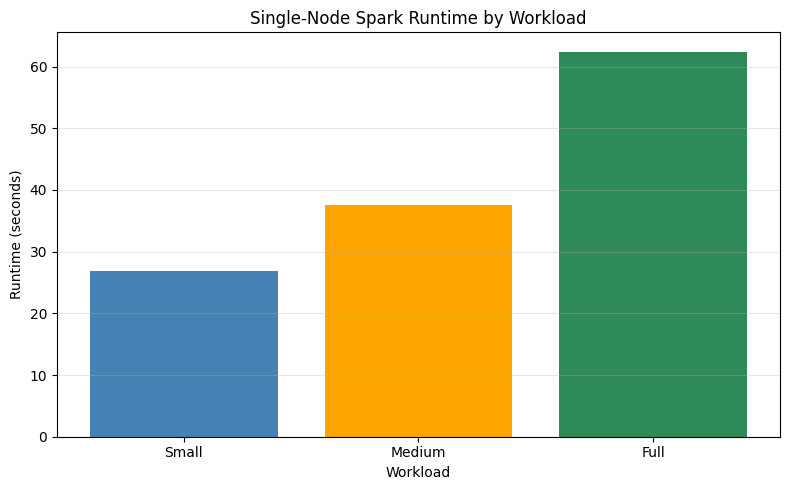

Figure 16.1 saved to:
/content/drive/MyDrive/CENG400_Energy_Project/person3_benchmarks/figure_16_1_runtime.png


In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(
    results["workload"],
    results["runtime_seconds"],
    color=["steelblue", "orange", "seagreen"]
)

plt.title("Single-Node Spark Runtime by Workload")
plt.xlabel("Workload")
plt.ylabel("Runtime (seconds)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

runtime_path = (
    "/content/drive/MyDrive/CENG400_Energy_Project/"
    "person3_benchmarks/figure_16_1_runtime.png"
)

plt.savefig(runtime_path, dpi=300)
plt.show()

print("Figure 16.1 saved to:")
print(runtime_path)

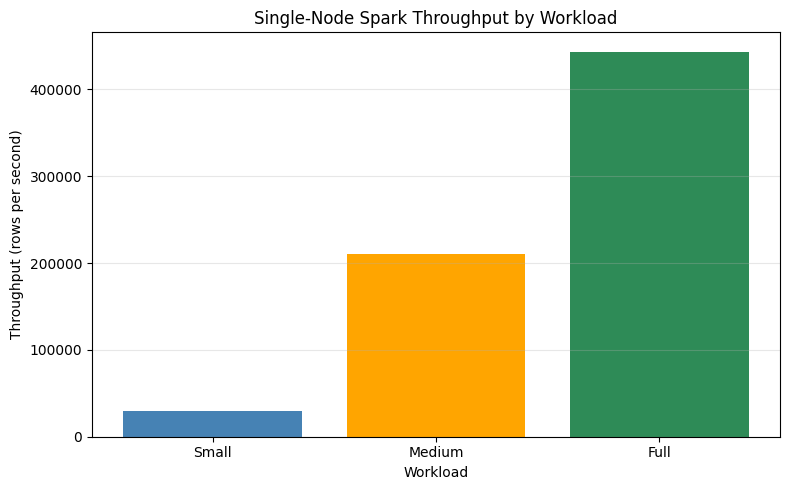

Figure 16.2 saved to:
/content/drive/MyDrive/CENG400_Energy_Project/person3_benchmarks/figure_16_2_throughput.png


In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(
    results["workload"],
    results["throughput_rows_per_second"],
    color=["steelblue", "orange", "seagreen"]
)

plt.title("Single-Node Spark Throughput by Workload")
plt.xlabel("Workload")
plt.ylabel("Throughput (rows per second)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

throughput_path = (
    "/content/drive/MyDrive/CENG400_Energy_Project/"
    "person3_benchmarks/figure_16_2_throughput.png"
)

plt.savefig(throughput_path, dpi=300)
plt.show()

print("Figure 16.2 saved to:")
print(throughput_path)

In [ ]:
from google.colab import auth
auth.authenticate_user()

!gcloud config list project


[core]
project (unset)

Your active configuration is: [default]


To take a quick anonymous survey, run:
  $ gcloud survey



In [ ]:
!gcloud projects list


PROJECT_ID                      NAME                    PROJECT_NUMBER  ENVIRONMENT
exalted-altar-512519-v5         My Project 6            453652792799
gen-lang-client-0938979101      Default Gemini Project  183837533272
medipal-91f2f                   medipal                 302507280269
project-9e33fa19-31ef-4577-81d  My First Project        238873341715
project-ac787ba4-222e-4a35-ab9  My First Project        605033018369


In [ ]:
!gcloud billing projects list


ERROR: (gcloud.billing.projects.list) argument --billing-account: Must be specified.
Usage: gcloud billing projects list --billing-account=ACCOUNT_ID [optional flags]
  optional flags may be  --filter | --help | --limit | --page-size | --sort-by

For detailed information on this command and its flags, run:
  gcloud billing projects list --help


In [ ]:
!gcloud billing accounts list

Listed 0 items.


In [ ]:
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/CENG400_Energy_Project")

In [ ]:
# ============================================================
# LOAD ANALYTICS AND FEATURES AGAIN
# ============================================================

from pyspark.sql import SparkSession

try:
    spark
except NameError:
    spark = (
        SparkSession.builder
        .appName("TableauExport")
        .config("spark.sql.shuffle.partitions", "200")
        .getOrCreate()
    )

PROJECT = "/content/drive/MyDrive/CENG400_Energy_Project"
OUT = f"{PROJECT}/person2_outputs"

analytics = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .option("recursiveFileLookup", True)
    .csv(f"{OUT}/analytics")
)

features = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .option("recursiveFileLookup", True)
    .csv(f"{OUT}/features")
)

print("Analytics columns:")
print(analytics.columns)

print("\nFeatures columns:")
print(features.columns)

print("\nSample analytics data:")
analytics.limit(3).show(truncate=False)

print("\nSample features data:")
features.limit(3).show(truncate=False)

Analytics columns:
['building_id', 'timestamp', 'energy_kwh', 'peak_demand_kw', 'minimum_demand_kw', 'average_demand_kw', 'readings', 'anomaly_count', 'load_factor']

Features columns:
['timestamp', 'building_id', 'kwh', 'rolling_24h_kwh', 'peak_hour', 'energy_intensity_kwh_sqm', 'anomaly_iqr']

Sample analytics data:


In [ ]:
# ============================================================
# LOAD ANALYTICS AND FEATURES CORRECTLY
# ============================================================

analytics = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .option("recursiveFileLookup", True)
    .option("pathGlobFilter", "*.csv")
    .csv(str(OUT / "analytics"))
)

features = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .option("recursiveFileLookup", True)
    .option("pathGlobFilter", "*.csv")
    .csv(str(OUT / "features"))
)

print("Analytics columns:")
print(analytics.columns)

print("\nFeatures columns:")
print(features.columns)

analytics.limit(3).show(truncate=False)
features.limit(3).show(truncate=False)

Analytics columns:
['building_id', 'timestamp', 'energy_kwh', 'peak_demand_kw', 'minimum_demand_kw', 'average_demand_kw', 'readings', 'anomaly_count', 'load_factor']

Features columns:
['timestamp', 'building_id', 'kwh', 'rolling_24h_kwh', 'peak_hour', 'energy_intensity_kwh_sqm', 'anomaly_iqr']
+--------------------+------------------------+----------+--------------+-----------------+-----------------+--------+-------------+-----------+
|building_id         |timestamp               |energy_kwh|peak_demand_kw|minimum_demand_kw|average_demand_kw|readings|anomaly_count|load_factor|
+--------------------+------------------------+----------+--------------+-----------------+-----------------+--------+-------------+-----------+
|Bear_assembly_Danial|2016-08-09T15:00:00.000Z|198.636   |198.636       |198.636          |198.636          |1       |0            |1.0        |
|Bear_assembly_Danial|2016-08-09T16:00:00.000Z|180.8558  |180.8558      |180.8558         |180.8558         |1       |0     

In [ ]:
# ============================================================
# EXPORT REMAINING TABLEAU FILES
# ============================================================

from pathlib import Path
from pyspark.sql import functions as F
from pyspark.sql.types import DoubleType

PROJECT = Path("/content/drive/MyDrive/CENG400_Energy_Project")
TABLEAU_DIR = PROJECT / "tableau_files"
TABLEAU_DIR.mkdir(exist_ok=True)

def save_tableau(df, name):
    path = str(TABLEAU_DIR / name)
    (
        df.coalesce(1)
        .write
        .mode("overwrite")
        .option("header", True)
        .csv(path)
    )
    print("Saved:", name)

# Safely parse and cast the analytics DataFrame columns using try_to_timestamp
analytics_cleaned = (
    analytics
    .withColumn("parsed_timestamp", F.try_to_timestamp("timestamp"))
    .withColumn("energy_kwh", F.col("energy_kwh").cast(DoubleType()))
    .filter(F.col("parsed_timestamp").isNotNull())
)

# Safely parse and cast the features DataFrame columns using try_to_timestamp
features_cleaned = (
    features
    .withColumn("parsed_timestamp", F.try_to_timestamp("timestamp"))
    .withColumn("kwh", F.col("kwh").cast(DoubleType()))
    .filter(F.col("parsed_timestamp").isNotNull())
)

# 1. Monthly energy
monthly = (
    analytics_cleaned
    .withColumn("month", F.date_format("parsed_timestamp", "yyyy-MM"))
    .groupBy("month")
    .agg(F.sum("energy_kwh").alias("total_energy_kwh"))
    .orderBy("month")
)
save_tableau(monthly, "monthly_energy")

# 2. Top 10 buildings
buildings = (
    analytics_cleaned
    .groupBy("building_id")
    .agg(F.sum("energy_kwh").alias("total_energy_kwh"))
    .orderBy(F.desc("total_energy_kwh"))
    .limit(10)
)
save_tableau(buildings, "building_energy")

# 3. Hourly pattern
hourly = (
    features_cleaned
    .withColumn("hour", F.hour("parsed_timestamp"))
    .groupBy("hour")
    .agg(F.avg("kwh").alias("average_kwh"))
    .orderBy("hour")
)
save_tableau(hourly, "hourly_energy")

# 4. Weekday versus weekend
weekday = (
    features_cleaned
    .withColumn(
        "weekday_weekend",
        F.when(F.dayofweek("parsed_timestamp").isin([1, 7]), "Weekend")
        .otherwise("Weekday")
    )
    .groupBy("weekday_weekend")
    .agg(
        F.avg("kwh").alias("average_kwh"),
        F.sum("kwh").alias("total_kwh")
    )
)
save_tableau(weekday, "weekday_weekend_energy")

# 5. Energy intensity
intensity = (
    features_cleaned
    .filter(F.col("energy_intensity_kwh_sqm").isNotNull())
    .groupBy("building_id")
    .agg(
        F.avg("energy_intensity_kwh_sqm")
        .alias("average_energy_intensity_kwh_sqm")
    )
    .orderBy(F.desc("average_energy_intensity_kwh_sqm"))
    .limit(20)
)
save_tableau(intensity, "energy_intensity")

# 6. Anomaly summary
anomalies = (
    features_cleaned
    .withColumn(
        "anomaly_flag",
        F.when(F.lower(F.col("anomaly_iqr").cast("string")) == "true", 1)
        .otherwise(0)
    )
    .groupBy("building_id")
    .agg(F.sum("anomaly_flag").alias("anomaly_count"))
    .orderBy(F.desc("anomaly_count"))
    .limit(20)
)
save_tableau(anomalies, "anomaly_summary")

print("All Tableau files created successfully.")

Saved: monthly_energy
Saved: building_energy
Saved: hourly_energy
Saved: weekday_weekend_energy
Saved: energy_intensity
Saved: anomaly_summary
All Tableau files created successfully.


In [ ]:
# ============================================================
# FIX ANALYTICS SCHEMA TEST
# ============================================================

analytics_files = list(
    (PROJECT / "person2_outputs" / "analytics").rglob("*.csv")
)

common_required = [
    "building_id",
    "energy_kwh",
    "peak_demand_kw",
    "minimum_demand_kw",
    "average_demand_kw",
    "readings",
    "anomaly_count",
    "load_factor"
]

analytics_schema_pass = False

for file in analytics_files:
    columns = pd.read_csv(file, nrows=0).columns.tolist()

    has_time_field = (
        "timestamp" in columns
        or "date" in columns
        or "week_start" in columns
        or "month_start" in columns
    )

    has_required_fields = all(
        column in columns
        for column in common_required
    )

    if has_time_field and has_required_fields:
        analytics_schema_pass = True
        break

# Remove the old failed analytics test
testing_results = testing_results[
    testing_results["test"] != "Analytics schema"
].copy()

# Add corrected result
testing_results.loc[len(testing_results)] = {
    "test": "Analytics schema",
    "actual": (
        "Valid analytical summary fields found"
        if analytics_schema_pass
        else "Required analytical fields missing"
    ),
    "status": "Pass" if analytics_schema_pass else "Fail"
}

display(testing_results)

testing_path = (
    PROJECT / "person3_benchmarks" /
    "end_to_end_test_results.csv"
)

testing_results.to_csv(testing_path, index=False)

print("Updated testing results saved to:")
print(testing_path)

if all(testing_results["status"] == "Pass"):
    print("PASS — All tested pipeline components are available.")
else:
    print("CHECK REQUIRED — Some tests failed.")

,test,actual,status
0,Electricity raw file,Found,Pass
1,Metadata raw file,Found,Pass
2,Person 2 curated output,Found,Pass
3,Person 2 quality output,Found,Pass
4,Person 2 analytics output,Found,Pass
5,Person 2 features output,Found,Pass
6,Tableau monthly_energy output,Found,Pass
7,Tableau building_energy output,Found,Pass
8,Tableau hourly_energy output,Found,Pass
9,Tableau weekday_weekend_energy output,Found,Pass


Updated testing results saved to:
/content/drive/MyDrive/CENG400_Energy_Project/person3_benchmarks/end_to_end_test_results.csv
PASS — All tested pipeline components are available.


In [ ]:
from pathlib import Path
import pandas as pd

analytics_folder = (
    PROJECT / "person2_outputs" / "analytics"
)

for file in list(analytics_folder.rglob("*.csv"))[:5]:
    columns = pd.read_csv(file, nrows=0).columns.tolist()
    print("\nFile:", file.name)
    print("Columns:", columns)


File: part-00001-fc5b3a93-3f09-42fe-a904-300f7d2abff6-c000.csv
Columns: ['building_id', 'date', 'energy_kwh', 'peak_demand_kw', 'minimum_demand_kw', 'average_demand_kw', 'readings', 'anomaly_count', 'load_factor']

File: part-00000-fc5b3a93-3f09-42fe-a904-300f7d2abff6-c000.csv
Columns: ['building_id', 'date', 'energy_kwh', 'peak_demand_kw', 'minimum_demand_kw', 'average_demand_kw', 'readings', 'anomaly_count', 'load_factor']

File: part-00003-fc5b3a93-3f09-42fe-a904-300f7d2abff6-c000.csv
Columns: ['building_id', 'date', 'energy_kwh', 'peak_demand_kw', 'minimum_demand_kw', 'average_demand_kw', 'readings', 'anomaly_count', 'load_factor']

File: part-00002-fc5b3a93-3f09-42fe-a904-300f7d2abff6-c000.csv
Columns: ['building_id', 'date', 'energy_kwh', 'peak_demand_kw', 'minimum_demand_kw', 'average_demand_kw', 'readings', 'anomaly_count', 'load_factor']

File: part-00000-88e844c1-968c-411b-9432-a7890c6ddafb-c000.csv
Columns: ['building_id', 'week_start', 'energy_kwh', 'peak_demand_kw', 'mini

In [ ]:
# ============================================================
# SECTION 22 — DATA QUALITY AND ANOMALY VALIDATION
# ============================================================

from pyspark.sql import functions as F
import pandas as pd

quality_results = []

quality_results.append({
    "check": "Analytics rows available",
    "result": analytics.limit(1).count() > 0,
    "status": "Pass"
})

quality_results.append({
    "check": "Features rows available",
    "result": features.limit(1).count() > 0,
    "status": "Pass"
})

required_analytics = [
    "building_id",
    "timestamp",
    "energy_kwh",
    "peak_demand_kw",
    "average_demand_kw",
    "anomaly_count"
]

required_features = [
    "timestamp",
    "building_id",
    "kwh",
    "rolling_24h_kwh",
    "peak_hour",
    "energy_intensity_kwh_sqm",
    "anomaly_iqr"
]

quality_results.append({
    "check": "Analytics schema",
    "result": all(c in analytics.columns for c in required_analytics),
    "status": "Pass"
    if all(c in analytics.columns for c in required_analytics)
    else "Fail"
})

quality_results.append({
    "check": "Features schema",
    "result": all(c in features.columns for c in required_features),
    "status": "Pass"
    if all(c in features.columns for c in required_features)
    else "Fail"
})

# Count anomalies without converting the full dataset to Pandas
anomaly_summary = (
    features
    .withColumn(
        "anomaly_flag",
        F.when(
            F.lower(F.col("anomaly_iqr").cast("string")) == "true",
            1
        ).otherwise(0)
    )
    .agg(F.sum("anomaly_flag").alias("total_anomalies"))
    .collect()[0]["total_anomalies"]
)

print("Total anomaly flags:", anomaly_summary)

quality_df = pd.DataFrame(quality_results)
display(quality_df)

quality_path = (
    PROJECT / "person3_benchmarks" /
    "data_quality_validation.csv"
)

quality_df.to_csv(quality_path, index=False)

print("Saved:", quality_path)

Total anomaly flags: 329902


,check,result,status
0,Analytics rows available,True,Pass
1,Features rows available,True,Pass
2,Analytics schema,True,Pass
3,Features schema,True,Pass


Saved: /content/drive/MyDrive/CENG400_Energy_Project/person3_benchmarks/data_quality_validation.csv


In [ ]:
# ============================================================
# SECTIONS 23–25 — MACHINE-LEARNING BONUS
# ============================================================

import time
import pandas as pd
import numpy as np

from pyspark.sql import functions as F
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Select only the columns needed for ML
ml_spark = (
    features
    .withColumn("hour", F.hour("timestamp"))
    .withColumn("month", F.month("timestamp"))
    .withColumn("day_of_week", F.dayofweek("timestamp"))
    .withColumn(
        "is_weekend",
        F.when(F.dayofweek("timestamp").isin([1, 7]), 1)
        .otherwise(0)
    )
    .select(
        "kwh",
        "rolling_24h_kwh",
        "peak_hour",
        "energy_intensity_kwh_sqm",
        "hour",
        "month",
        "day_of_week",
        "is_weekend"
    )
    .dropna()
    .sample(False, 0.01, seed=42)
    .limit(20000)
)

ml_data = ml_spark.toPandas()

print("ML sample size:", len(ml_data))

# Prepare features and target
X = ml_data[
    [
        "rolling_24h_kwh",
        "peak_hour",
        "energy_intensity_kwh_sqm",
        "hour",
        "month",
        "day_of_week",
        "is_weekend"
    ]
]

y = ml_data["kwh"]

# Replace infinite values and missing values
X = X.replace([np.inf, -np.inf], np.nan).fillna(0)
y = y.replace([np.inf, -np.inf], np.nan).fillna(0)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

ml_results = []

# ------------------------------------------------------------
# Linear Regression
# ------------------------------------------------------------

start = time.perf_counter()

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

linear_training_time = time.perf_counter() - start

start = time.perf_counter()

linear_predictions = linear_model.predict(X_test)

linear_prediction_time = time.perf_counter() - start

linear_mae = mean_absolute_error(y_test, linear_predictions)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_predictions))
linear_r2 = r2_score(y_test, linear_predictions)

ml_results.append({
    "model": "Linear Regression",
    "mae": linear_mae,
    "rmse": linear_rmse,
    "r2": linear_r2,
    "training_time_seconds": linear_training_time,
    "prediction_time_seconds": linear_prediction_time
})

# ------------------------------------------------------------
# Artificial Neural Network
# ------------------------------------------------------------

start = time.perf_counter()

ann_model = MLPRegressor(
    hidden_layer_sizes=(32, 16),
    activation="relu",
    solver="adam",
    max_iter=100,
    random_state=42,
    early_stopping=True
)

ann_model.fit(X_train, y_train)

ann_training_time = time.perf_counter() - start

start = time.perf_counter()

ann_predictions = ann_model.predict(X_test)

ann_prediction_time = time.perf_counter() - start

ann_mae = mean_absolute_error(y_test, ann_predictions)
ann_rmse = np.sqrt(mean_squared_error(y_test, ann_predictions))
ann_r2 = r2_score(y_test, ann_predictions)

ml_results.append({
    "model": "Artificial Neural Network",
    "mae": ann_mae,
    "rmse": ann_rmse,
    "r2": ann_r2,
    "training_time_seconds": ann_training_time,
    "prediction_time_seconds": ann_prediction_time
})

# ------------------------------------------------------------
# Display and save results
# ------------------------------------------------------------

ml_results_df = pd.DataFrame(ml_results)

display(ml_results_df)

ml_path = (
    PROJECT / "person3_machine_learning_results.csv"
)

ml_results_df.to_csv(ml_path, index=False)

print("ML results saved to:")
print(ml_path)

ML sample size: 20000


,model,mae,rmse,r2,training_time_seconds,prediction_time_seconds
0,Linear Regression,23.171104,52.336408,0.956215,0.050963,0.014379
1,Artificial Neural Network,21.618917,54.683326,0.952200,1.406210,0.009692


ML results saved to:
/content/drive/MyDrive/CENG400_Energy_Project/person3_machine_learning_results.csv
